In [4]:
import duckdb

con = duckdb.connect("../data/processed/osm.duckdb")

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

print("DuckDB ready!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

DuckDB ready!


In [5]:
result = con.execute("""
    SELECT *
    FROM ST_ReadOSM('../data/raw/osm/nsw.osm.pbf')
    LIMIT 5
""").df()

display(result)

,kind,id,tags,refs,lat,lon,ref_roles,ref_types
0,node,324883,<NA>,<NA>,-33.917676,151.188840,<NA>,<NA>
1,node,324884,"{'button_operated': 'yes', 'crossing': 'traffi...",<NA>,-33.910857,151.194921,<NA>,<NA>
2,node,624529,<NA>,<NA>,-33.897739,151.227741,<NA>,<NA>
3,node,624532,<NA>,<NA>,-33.897237,151.228919,<NA>,<NA>
4,node,624534,<NA>,<NA>,-33.897323,151.227973,<NA>,<NA>


In [6]:
con.execute("""
    CREATE OR REPLACE TABLE osm_features AS
    SELECT
        kind,
        id,
        tags,
        lat,
        lon,
        refs
    FROM ST_ReadOSM('../data/raw/osm/nsw.osm.pbf')
    WHERE
        tags['shop'] IS NOT NULL
        OR tags['amenity'] IN ('cafe', 'restaurant')
        OR tags['highway'] = 'bus_stop'
        OR tags['railway'] = 'station'
        OR tags['leisure'] = 'park'
""")

print(
    "Extracted objects:",
    con.execute("SELECT COUNT(*) FROM osm_features").fetchone()[0]
)

Extracted objects: 95293


In [7]:
## INSPECT EXTRACTION RESULTS
sample = con.execute("""
    SELECT
        kind,
        id,
        tags['name'] AS name,
        tags['shop'] AS shop,
        tags['amenity'] AS amenity,
        tags['highway'] AS highway,
        tags['railway'] AS railway,
        tags['leisure'] AS leisure,
        lat,
        lon
    FROM osm_features
    LIMIT 20
""").df()

display(sample)

,kind,id,name,shop,amenity,highway,railway,leisure,lat,lon
0,node,13757642,Singapore Famous BBQ Pork,NaN,restaurant,NaN,NaN,NaN,-33.880777,151.203912
1,node,14758812,Anzac Pde Terminus,NaN,NaN,bus_stop,NaN,NaN,-33.987968,151.233587
2,node,17027753,Coles,supermarket,NaN,NaN,NaN,NaN,-31.477181,152.914608
3,node,17027848,Public Reserve,NaN,NaN,NaN,NaN,park,-31.473039,152.929881
4,node,17029400,Waniora Shopping Village,mall,NaN,NaN,NaN,NaN,-31.454684,152.917873
5,node,17078282,Settlers Inn,alcohol,NaN,NaN,NaN,NaN,-31.429973,152.886318
6,node,17087666,NaN,NaN,cafe,NaN,NaN,NaN,-32.801703,151.717042
7,node,17134732,Coles,supermarket,NaN,NaN,NaN,NaN,-31.648565,152.796294
8,node,18840881,Clovelly Road Terminus,NaN,NaN,bus_stop,NaN,NaN,-33.914708,151.266687
9,node,18845339,Seasalt Cafe,NaN,cafe,NaN,NaN,NaN,-33.914337,151.266760


In [8]:
display(
    con.execute("""
        SELECT kind, COUNT(*) AS count
        FROM osm_features
        GROUP BY kind
        ORDER BY count DESC
    """).df()
)

,kind,count
0,node,74335
1,way,20339
2,relation,619


In [10]:
import geopandas as gpd
import fiona


path = "../data/processed/osm/sydney_pois.gpkg"

print(fiona.listlayers(path))

['points', 'lines', 'multipolygons', 'multilinestrings', 'other_relations']


In [11]:
points = gpd.read_file(path, layer="points")

print("Number of points:", len(points))
print("Columns:", points.columns.tolist())

display(points.head())

Number of points: 42741
Columns: ['osm_id', 'name', 'barrier', 'highway', 'ref', 'address', 'is_in', 'place', 'man_made', 'other_tags', 'geometry']


,osm_id,name,barrier,highway,ref,address,is_in,place,man_made,other_tags,geometry
0,8099424,Yurong Gate,gate,NaN,K,None,NaN,NaN,NaN,"""opening_hours""=>""Nov-Feb Mo-Su 07:00-20:00 , ...",POINT (151.22036 -33.86229)
1,12056262,Robertson Road Gates,gate,NaN,NaN,None,NaN,NaN,NaN,"""old_name""=>""Showground Gates""",POINT (151.22684 -33.89725)
2,13757642,Singapore Famous BBQ Pork,NaN,NaN,NaN,None,NaN,NaN,NaN,"""amenity""=>""restaurant""",POINT (151.20391 -33.88078)
3,13814129,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,"""source:location""=>""nearmap""",POINT (151.27303 -33.85327)
4,13816944,Mrs Macquarie's Point / Yurong,NaN,NaN,NaN,None,NaN,NaN,NaN,"""name:aus""=>""Yurong"",""name:en""=>""Mrs Macquarie...",POINT (151.22216 -33.85903)


In [12]:
polygons = gpd.read_file(path, layer="multipolygons")

print("Number of polygons:", len(polygons))
print("Columns:", polygons.columns.tolist())

display(polygons.head())

Number of polygons: 9668
Columns: ['osm_id', 'osm_way_id', 'name', 'type', 'aeroway', 'amenity', 'admin_level', 'barrier', 'boundary', 'building', 'craft', 'geological', 'historic', 'land_area', 'landuse', 'leisure', 'man_made', 'military', 'natural', 'office', 'place', 'shop', 'sport', 'tourism', 'other_tags', 'geometry']


,osm_id,osm_way_id,name,type,aeroway,amenity,admin_level,barrier,boundary,building,...,man_made,military,natural,office,place,shop,sport,tourism,other_tags,geometry
0,1173507,NaN,Gilchrist Park,multipolygon,None,NaN,None,NaN,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,"""source:name""=>""historical""","MULTIPOLYGON (((151.11023 -33.94143, 151.11016..."
1,1253061,NaN,Riverine Park,multipolygon,None,NaN,None,NaN,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,"""source:name""=>""survey"",""wikidata""=>""Q21934908""","MULTIPOLYGON (((151.15047 -33.94467, 151.15085..."
2,1253301,NaN,Parkside Drive Reserve,multipolygon,None,NaN,None,NaN,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,"""layer""=>""-1"",""source:name""=>""survey""","MULTIPOLYGON (((151.11824 -33.98166, 151.11965..."
3,1285347,NaN,Don Lucas Reserve,multipolygon,None,NaN,None,NaN,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,"""source:name""=>""survey""","MULTIPOLYGON (((151.16175 -34.04183, 151.16193..."
4,1311326,NaN,John McKinn Park,multipolygon,None,NaN,None,NaN,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,"""source:name""=>""survey"",""wikidata""=>""Q21931004""","MULTIPOLYGON (((151.15892 -34.04452, 151.15886..."


In [13]:
import geopandas as gpd
import pandas as pd

path = "../data/processed/osm/sydney_pois.gpkg"

points = gpd.read_file(path, layer="points")
polygons = gpd.read_file(path, layer="multipolygons")

display(points[["name", "other_tags"]].head(10))
display(polygons[["name", "shop", "other_tags"]].head(10))

,name,other_tags
0,Yurong Gate,"""opening_hours""=>""Nov-Feb Mo-Su 07:00-20:00 , ..."
1,Robertson Road Gates,"""old_name""=>""Showground Gates"""
2,Singapore Famous BBQ Pork,"""amenity""=>""restaurant"""
3,NaN,"""source:location""=>""nearmap"""
4,Mrs Macquarie's Point / Yurong,"""name:aus""=>""Yurong"",""name:en""=>""Mrs Macquarie..."
5,St Leonards,"""fare_gates""=>""yes"",""network""=>""Sydney Trains""..."
6,Anzac Pde Terminus,"""bench""=>""yes"",""bin""=>""yes"",""bus""=>""yes"",""gtfs..."
7,NaN,"""crossing""=>""uncontrolled"",""crossing:island""=>..."
8,Marrickville,"""fare_gates""=>""no"",""network""=>""Sydney Metro"",""..."
9,Green Square,"""fare_gates""=>""yes"",""location""=>""underground"",..."


,name,shop,other_tags
0,Gilchrist Park,NaN,"""source:name""=>""historical"""
1,Riverine Park,NaN,"""source:name""=>""survey"",""wikidata""=>""Q21934908"""
2,Parkside Drive Reserve,NaN,"""layer""=>""-1"",""source:name""=>""survey"""
3,Don Lucas Reserve,NaN,"""source:name""=>""survey"""
4,John McKinn Park,NaN,"""source:name""=>""survey"",""wikidata""=>""Q21931004"""
5,Cook Park,NaN,NaN
6,Henry Kitchen Park,NaN,"""source:name""=>""NSW LPI"",""wikidata""=>""Q21968259"""
7,Bill Mitchell Park,NaN,"""foot""=>""yes"",""wikidata""=>""Q21925391"""
8,Morrison Bay Park,NaN,"""layer""=>""-1"",""source:name""=>""local_knowledge""..."
9,Ambarvale Sports Complex,NaN,"""addr:postcode""=>""2560"",""addr:state""=>""NSW"",""a..."


In [14]:
import re

def get_osm_tag(other_tags, key):
    if pd.isna(other_tags):
        return None

    match = re.search(
        rf'"{re.escape(key)}"=>"([^"]*)"',
        str(other_tags)
    )

    return match.group(1) if match else None

In [15]:
tag_columns = [
    "shop",
    "amenity",
    "highway",
    "railway",
    "leisure"
]

for df in [points, polygons]:
    for tag in tag_columns:
        extracted = df["other_tags"].apply(
            lambda x: get_osm_tag(x, tag)
        )

        if tag in df.columns:
            df[tag] = df[tag].fillna(extracted)
        else:
            df[tag] = extracted

In [16]:
for tag in tag_columns:
    print(f"\n{tag}")
    print(points[tag].value_counts().head(10))
    print(polygons[tag].value_counts().head(10))


shop
shop
supermarket    782
hairdresser    779
clothes        761
convenience    589
bakery         465
alcohol        423
beauty         385
vacant         354
car_repair     281
massage        239
Name: count, dtype: int64
shop
convenience       385
mall              300
supermarket       133
car_repair        130
car               126
yes                94
alcohol            66
hairdresser        51
doityourself       46
storage_rental     39
Name: count, dtype: int64

amenity
amenity
restaurant          3458
cafe                2885
parking_entrance     206
loading_dock          95
pharmacy              24
fuel                  13
shelter                9
bench                  8
fast_food              7
parking                5
Name: count, dtype: int64
amenity
restaurant      298
cafe            241
fuel             17
parking           4
school            2
pharmacy          2
traffic_park      1
bbq               1
ice_cream         1
pub               1
Name: count, dtype: i

In [17]:
# Save original park polygons for later
park_polygons = polygons[
    polygons["leisure"] == "park"
].copy()

# Convert polygons into representative points
polygon_points = polygons.copy()
polygon_points["geometry"] = (
    polygon_points.geometry.representative_point()
)

# Combine all objects
osm_all = pd.concat(
    [
        points,
        polygon_points
    ],
    ignore_index=True
)

osm_all = gpd.GeoDataFrame(
    osm_all,
    geometry="geometry",
    crs=points.crs
)

print("Combined features:", len(osm_all))

Combined features: 52409


In [18]:
hex_grid = gpd.read_file(
    "../data/processed/sydney_hex_grid.geojson"
)

# Use projected coordinates in metres
hex_grid = hex_grid.to_crs("EPSG:7856")
osm_all = osm_all.to_crs("EPSG:7856")
park_polygons = park_polygons.to_crs("EPSG:7856")

# Create a 500 m buffer around the hexagon grid
study_buffer = hex_grid.geometry.union_all().buffer(500)

# Retain nearby OSM points
osm_sydney = osm_all[
    osm_all.geometry.intersects(study_buffer)
].copy()

# Retain nearby park polygons
parks_sydney = park_polygons[
    park_polygons.geometry.intersects(study_buffer)
].copy()

print("OSM features near study area:", len(osm_sydney))
print("Park polygons near study area:", len(parks_sydney))

OSM features near study area: 48309
Park polygons near study area: 6493


In [19]:
osm_sydney["is_shop"] = osm_sydney["shop"].notna()

osm_sydney["is_food"] = osm_sydney["amenity"].isin([
    "cafe",
    "restaurant"
])

osm_sydney["is_bus_stop"] = (
    osm_sydney["highway"] == "bus_stop"
)

osm_sydney["is_train_station"] = (
    osm_sydney["railway"] == "station"
)

osm_sydney["is_park"] = (
    osm_sydney["leisure"] == "park"
)

for col in [
    "is_shop",
    "is_food",
    "is_bus_stop",
    "is_train_station",
    "is_park"
]:
    print(col, osm_sydney[col].sum())

is_shop 11973
is_food 6580
is_bus_stop 21465
is_train_station 199
is_park 6551


In [20]:
hex_centres = hex_grid[
    ["hex_id", "geometry"]
].copy()

hex_centres["geometry"] = (
    hex_centres.geometry.centroid
)

In [21]:
def count_nearby_features(hex_centres, osm_features, radius, category):
    # Buffer each hexagon centre
    buffers = hex_centres.copy()
    buffers["geometry"] = buffers.geometry.buffer(radius)

    # Only select features in the requested category
    selected = osm_features[
        osm_features[category]
    ].copy()

    # Spatial join: which features fall inside each buffer?
    joined = gpd.sjoin(
        buffers,
        selected[["geometry"]],
        how="left",
        predicate="intersects"
    )

    # Count actual matches (exclude unmatched rows)
    counts = (
        joined.groupby("hex_id")["index_right"]
        .count()
    )

    return counts

In [22]:
categories = [
    "is_shop",
    "is_food",
    "is_bus_stop",
    "is_train_station",
    "is_park"
]

for category in categories:
    for radius in [250, 500]:
        column_name = f"{category[3:]}_{radius}m"

        counts = count_nearby_features(
            hex_centres,
            osm_sydney,
            radius,
            category
        )

        hex_grid[column_name] = (
            hex_grid["hex_id"]
            .map(counts)
            .fillna(0)
            .astype(int)
        )

        print(column_name, "done")

shop_250m done
shop_500m done
food_250m done
food_500m done
bus_stop_250m done
bus_stop_500m done
train_station_250m done
train_station_500m done
park_250m done
park_500m done


In [23]:
population_features = pd.read_csv(
    "../data/processed/sydney_hex_features.csv"
)

hex_grid = hex_grid.merge(
    population_features[
        ["hex_id", "population_est", "population_density"]
    ],
    on="hex_id",
    how="left",
    validate="one_to_one"
)

display(hex_grid.head())

,hex_id,toilet_count,geometry,shop_250m,shop_500m,food_250m,food_500m,bus_stop_250m,bus_stop_500m,train_station_250m,train_station_500m,park_250m,park_500m,population_est,population_density
0,89be081a427ffff,0,"POLYGON ((284438.794 6226149.21, 284388.726 62...",0,0,0,0,0,0,0,0,0,0,2.573064,20.323744
1,89be081b483ffff,0,"POLYGON ((290402.669 6230927.649, 290352.602 6...",0,0,0,0,1,6,0,0,0,4,290.758144,2296.466691
2,89be081a053ffff,0,"POLYGON ((284845.693 6228619.375, 284795.628 6...",0,0,0,0,0,0,0,0,0,0,61.694254,487.304332
3,89be08c5b13ffff,0,"POLYGON ((289472.471 6229014.762, 289422.403 6...",0,0,0,0,3,10,0,0,2,6,339.654950,2682.672676
4,89be081b5bbffff,0,"POLYGON ((287156.609 6230513.424, 287106.545 6...",0,0,0,0,0,0,0,0,0,0,1.847987,14.596371


In [24]:
hex_grid.to_file(
    "../data/processed/sydney_hex_features_osm.geojson",
    driver="GeoJSON"
)

hex_grid.drop(columns="geometry").to_csv(
    "../data/processed/sydney_hex_features_osm.csv",
    index=False
)

print("Saved:", len(hex_grid), "hexagons")

Saved: 16228 hexagons


In [25]:
feature_columns = [
    "shop_500m",
    "food_500m",
    "bus_stop_500m",
    "train_station_500m",
    "park_500m"
]

display(
    hex_grid[feature_columns].describe()
)

,shop_500m,food_500m,bus_stop_500m,train_station_500m,park_500m
count,16228.000000,16228.000000,16228.000000,16228.000000,16228.000000
mean,4.376695,2.380022,7.710500,0.071173,2.315319
std,14.995713,10.272480,6.975999,0.291283,2.605008
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,0.000000,0.000000
50%,0.000000,0.000000,7.000000,0.000000,2.000000
75%,2.000000,1.000000,12.000000,0.000000,4.000000
max,336.000000,248.000000,49.000000,6.000000,40.000000


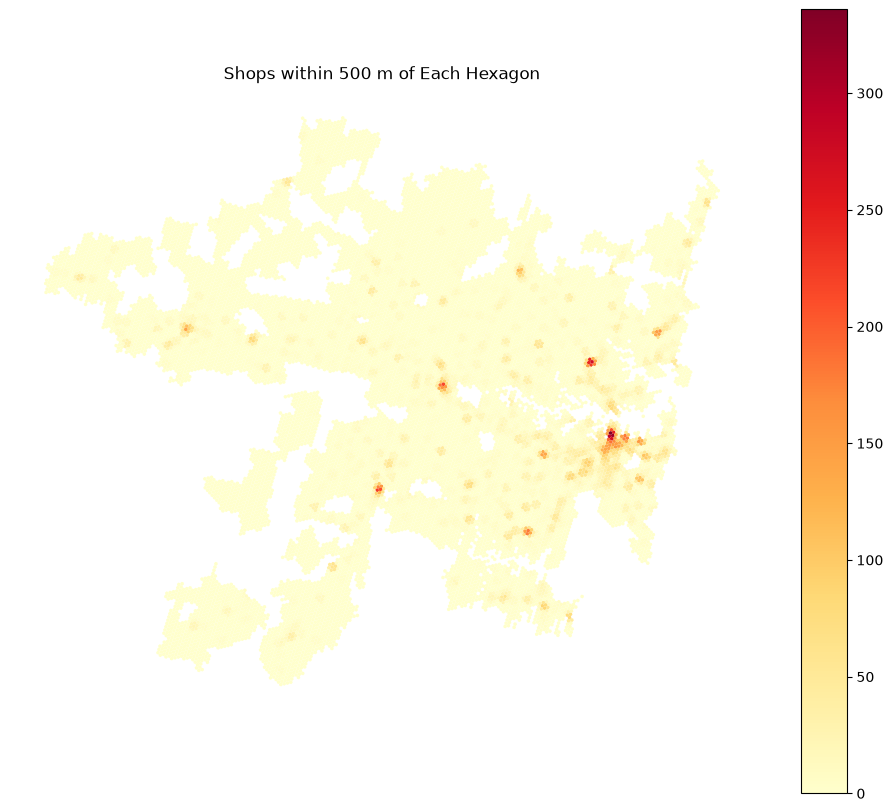

In [26]:
fig, ax = plt.subplots(figsize=(12, 12))

hex_grid.plot(
    column="shop_500m",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    linewidth=0
)

ax.set_title("Shops within 500 m of Each Hexagon")
ax.set_axis_off()

plt.show()

In [27]:
## VERIFY

In [28]:
columns = [
    "hex_id",
    "shop_500m",
    "food_500m",
    "bus_stop_500m",
    "train_station_500m",
    "park_500m"
]

display(
    hex_grid[columns]
    .sort_values("shop_500m", ascending=False)
    .head(10)
)

display(
    hex_grid[columns]
    .sort_values("bus_stop_500m", ascending=False)
    .head(10)
)

,hex_id,shop_500m,food_500m,bus_stop_500m,train_station_500m,park_500m
9307,89be0e35ca3ffff,336,221,49,1,2
5047,89be0e35cb3ffff,314,180,42,1,1
11954,89be0e35cb7ffff,288,190,35,1,2
10861,89be0e27447ffff,271,172,25,1,2
7949,89be0e3434fffff,266,186,38,1,3
2930,89be0e35cbbffff,246,174,33,1,4
7094,89be0e27473ffff,242,163,28,1,5
4969,89be0e2747bffff,239,143,31,0,4
3244,89be08c8bb7ffff,225,34,20,0,5
2952,89be0e2740bffff,225,154,22,1,2


,hex_id,shop_500m,food_500m,bus_stop_500m,train_station_500m,park_500m
9307,89be0e35ca3ffff,336,221,49,1,2
13845,89be0e3431bffff,110,133,43,2,6
2210,89be0e3430bffff,151,209,43,3,7
5047,89be0e35cb3ffff,314,180,42,1,1
7176,89be0e35cabffff,210,202,42,2,6
4696,89be08cb44bffff,4,0,42,0,2
3452,89be0e35307ffff,4,10,42,0,3
5827,89be0e34357ffff,146,144,41,2,7
11627,89be0e3460fffff,99,26,40,1,4
14845,89be0e34353ffff,145,130,40,0,8


In [29]:
top_shops = hex_grid.nlargest(1, "shop_500m")
top_buses = hex_grid.nlargest(1, "bus_stop_500m")

for name, data in [
    ("Most shops", top_shops),
    ("Most bus stops", top_buses)
]:
    centre = data.geometry.centroid.to_crs("EPSG:4326").iloc[0]
    print(name, ":", centre.y, centre.x)

Most shops : -33.868060835963014 151.20636209327412
Most bus stops : -33.868060835963014 151.20636209327412


In [30]:
study_bounds = hex_grid.to_crs("EPSG:4326").total_bounds

print("Study bounds [west, south, east, north]:")
print(study_bounds)

print("Required bounds with 1 km buffer:")
print(
    hex_grid.to_crs("EPSG:7856")
    .geometry.union_all()
    .buffer(1000)
    .bounds
)

Study bounds [west, south, east, north]:
[150.52237659 -34.1184649  151.34449592 -33.54104333]
Required bounds with 1 km buffer:
(269379.38939661405, 6221522.833004005, 347439.8782121216, 6287671.514440611)


In [31]:
from shapely.geometry import box
from shapely.ops import transform
from pyproj import Transformer

download_bbox = box(150.45, -34.25, 151.40, -33.35)

study_with_buffer = (
    hex_grid.to_crs("EPSG:4326")
    .to_crs("EPSG:7856")
    .geometry.union_all()
    .buffer(1000)
)

transformer = Transformer.from_crs(
    "EPSG:7856", "EPSG:4326", always_xy=True
)

from shapely.ops import transform

buffer_wgs84 = transform(transformer.transform, study_with_buffer)

print(
    "Fully covered by original download box:",
    download_bbox.covers(buffer_wgs84)
)

Fully covered by original download box: True


/var/folders/lr/yyv3976n5xzd048g7z258q9w0000gn/T/ipykernel_2551/876665814.py:20: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  buffer_wgs84 = transform(transformer.transform, study_with_buffer)


In [32]:
import geopandas as gpd

study = gpd.read_file(
    "../data/processed/sydney_study_sa1_final.geojson"
).to_crs("EPSG:7856")

hex_grid = hex_grid.to_crs("EPSG:7856")

study_polygon = study.geometry.union_all()

centres_inside = (
    hex_grid.geometry.centroid.within(study_polygon)
)

print("Total hexagons:", len(hex_grid))
print("Centres inside study area:", centres_inside.sum())
print("Centres outside study area:", (~centres_inside).sum())

Total hexagons: 16228
Centres inside study area: 16228
Centres outside study area: 0


In [33]:
## INSPECT HIGH COUNTS
# Make sure hex_grid is in metres
hex_grid = hex_grid.to_crs("EPSG:7856")

for feature in [
    "shop_500m",
    "food_500m",
    "bus_stop_500m"
]:
    top = hex_grid.nlargest(5, feature).copy()

    centres = top.geometry.centroid.to_crs("EPSG:4326")

    top["latitude"] = centres.y
    top["longitude"] = centres.x

    print(f"\nTop 5 hexagons: {feature}")

    display(top[
        ["hex_id", feature, "latitude", "longitude"]
    ])



Top 5 hexagons: shop_500m


,hex_id,shop_500m,latitude,longitude
9307,89be0e35ca3ffff,336,-33.868061,151.206362
5047,89be0e35cb3ffff,314,-33.870614,151.209138
11954,89be0e35cb7ffff,288,-33.871336,151.205088
10861,89be0e27447ffff,271,-33.795567,151.185578
7949,89be0e3434fffff,266,-33.873889,151.207864



Top 5 hexagons: food_500m


,hex_id,food_500m,latitude,longitude
10080,89be0e34347ffff,248,-33.877165,151.206591
4231,89be0e3437bffff,224,-33.874611,151.203815
6345,89be0e34373ffff,221,-33.877887,151.202541
9307,89be0e35ca3ffff,221,-33.868061,151.206362
2210,89be0e3430bffff,209,-33.880440,151.205317



Top 5 hexagons: bus_stop_500m


,hex_id,bus_stop_500m,latitude,longitude
9307,89be0e35ca3ffff,49,-33.868061,151.206362
2210,89be0e3430bffff,43,-33.880440,151.205317
13845,89be0e3431bffff,43,-33.882993,151.208093
3452,89be0e35307ffff,42,-33.833521,151.246156
4696,89be08cb44bffff,42,-33.952031,151.128400


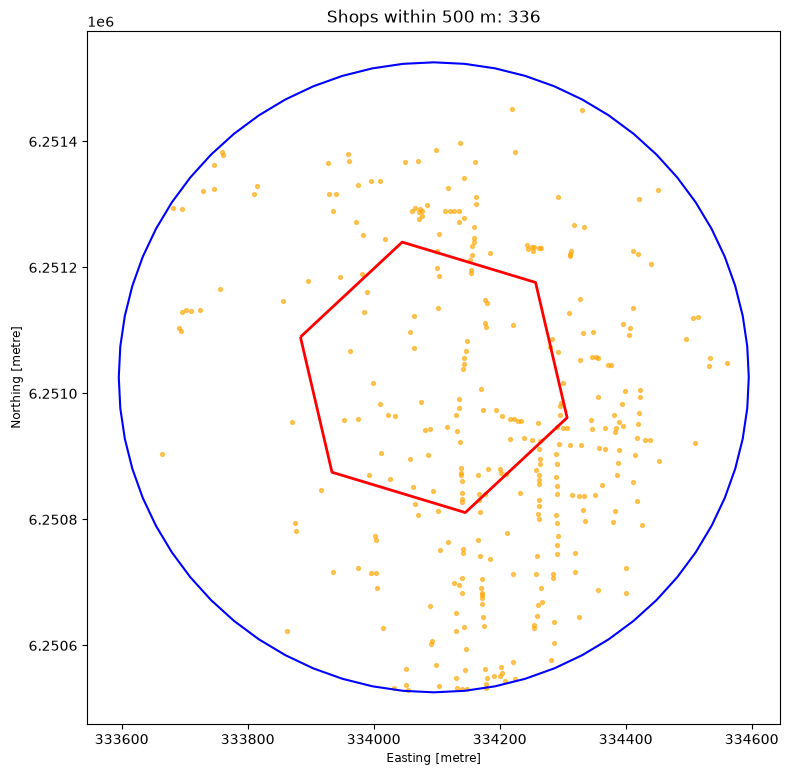

In [36]:
import matplotlib.pyplot as plt

top_hex = hex_grid.nlargest(1, "shop_500m")
centre = top_hex.geometry.centroid.iloc[0]

buffer_500 = centre.buffer(500)

nearby_shops = osm_sydney[
    osm_sydney["is_shop"]
    & osm_sydney.geometry.intersects(buffer_500)
]

fig, ax = plt.subplots(figsize=(9, 9))

gpd.GeoSeries([buffer_500], crs=hex_grid.crs).boundary.plot(
    ax=ax,
    color="blue"
)

top_hex.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

nearby_shops.plot(
    ax=ax,
    color="orange",
    markersize=8,
    alpha=0.6
)

ax.set_title(f"Shops within 500 m: {len(nearby_shops)}")
ax.set_aspect("equal")
plt.show()

In [37]:
print("Point columns:")
print(points.columns.tolist())

print("\nPolygon columns:")
print(polygons.columns.tolist())

display(points[["osm_id", "name"]].head())
display(polygons[["osm_id", "osm_way_id", "name"]].head())

Point columns:
['osm_id', 'name', 'barrier', 'highway', 'ref', 'address', 'is_in', 'place', 'man_made', 'other_tags', 'geometry', 'shop', 'amenity', 'railway', 'leisure']

Polygon columns:
['osm_id', 'osm_way_id', 'name', 'type', 'aeroway', 'amenity', 'admin_level', 'barrier', 'boundary', 'building', 'craft', 'geological', 'historic', 'land_area', 'landuse', 'leisure', 'man_made', 'military', 'natural', 'office', 'place', 'shop', 'sport', 'tourism', 'other_tags', 'geometry', 'highway', 'railway']


,osm_id,name
0,8099424,Yurong Gate
1,12056262,Robertson Road Gates
2,13757642,Singapore Famous BBQ Pork
3,13814129,NaN
4,13816944,Mrs Macquarie's Point / Yurong


,osm_id,osm_way_id,name
0,1173507,NaN,Gilchrist Park
1,1253061,NaN,Riverine Park
2,1253301,NaN,Parkside Drive Reserve
3,1285347,NaN,Don Lucas Reserve
4,1311326,NaN,John McKinn Park


In [38]:
print(
    "Duplicate point OSM IDs:",
    points["osm_id"].duplicated().sum()
)

print(
    "Duplicate polygon identifiers:",
    polygons[["osm_id", "osm_way_id"]]
    .duplicated().sum()
)

Duplicate point OSM IDs: 0
Duplicate polygon identifiers: 0


In [41]:
### SHOP STATUS DISTRIBUTION
shop_distribution = (
    osm_sydney.loc[
        osm_sydney["shop"].notna(),
        "shop"
    ]
    .value_counts()
)

display(shop_distribution.head(40))

print("Total shop-tagged objects:", shop_distribution.sum())

shop
convenience         924
supermarket         849
hairdresser         800
clothes             767
bakery              465
alcohol             448
beauty              394
car_repair          381
vacant              357
mall                294
massage             247
car                 230
yes                 220
butcher             216
jewelry             175
newsagent           169
furniture           165
greengrocer         144
florist             144
shoes               140
department_store    136
variety_store       135
tobacco             127
electronics         122
gift                121
laundry             111
dry_cleaning        107
charity             104
bicycle             101
mobile_phone         91
houseware            90
pet                  88
car_parts            87
optician             85
seafood              83
pastry               82
chemist              80
travel_agency        77
hardware             74
doityourself         73
Name: count, dtype: int64

Total shop-tagged objects: 11973


In [ ]:
## Exclude vacant shops from data
excluded_shop_tags = {
    "vacant",
}

osm_sydney["is_active_shop"] = (
    osm_sydney["shop"].notna()
    & ~osm_sydney["shop"].isin(excluded_shop_tags)
)

print("Original shop objects:", osm_sydney["is_shop"].sum())
print("Active/known-type shop objects:", osm_sydney["is_active_shop"].sum())
print(
    "Excluded:",
    osm_sydney["is_shop"].sum()
    - osm_sydney["is_active_shop"].sum()
)

Original shop objects: 11973
Active/known-type shop objects: 11616
Excluded: 357


In [45]:
print(osm_sydney[[
    "osm_id", "name", "shop", "amenity", "geometry"
]].head())

     osm_id                            name shop     amenity  \
0   8099424                     Yurong Gate  NaN         NaN   
1  12056262            Robertson Road Gates  NaN         NaN   
2  13757642       Singapore Famous BBQ Pork  NaN  restaurant   
3  13814129                             NaN  NaN         NaN   
4  13816944  Mrs Macquarie's Point / Yurong  NaN         NaN   

                         geometry  
0  POINT (335378.932 6251687.667)  
1  POINT (336045.879 6247821.164)  
2  POINT (333893.421 6249611.462)  
3   POINT (340235.281 6252771.92)  
4  POINT (335539.682 6252052.277)  


In [48]:
# Restrict to named shops
named_shops = osm_sydney[
    osm_sydney["is_active_shop"]
    & osm_sydney["name"].notna()
].copy()

# Find shops within 10 metres of each other
nearby_pairs = gpd.sjoin(
    named_shops,
    named_shops,
    how="inner",
    predicate="dwithin",
    distance=10,
    lsuffix="left",
    rsuffix="right"
)

# Remove self-matches and mirrored pairs
nearby_pairs = nearby_pairs[
    nearby_pairs.index < nearby_pairs["index_right"]
].copy()

# Same name and same shop category
suspected_duplicates = nearby_pairs[
    (nearby_pairs["name_left"] == nearby_pairs["name_right"])
    & (nearby_pairs["shop_left"] == nearby_pairs["shop_right"])
]

print("Suspicious duplicate pairs:", len(suspected_duplicates))

display(
    suspected_duplicates[
        ["name_left", "shop_left", "osm_id_left", "osm_id_right"]
    ].head(20)
)

Suspicious duplicate pairs: 6


,name_left,shop_left,osm_id_left,osm_id_right
10364,Industrie Clothing,clothes,4860772923,5931284403
10364,Industrie Clothing,clothes,4860772923,5931284400
12837,Industrie Clothing,clothes,5931284400,5931284403
21782,BP,convenience,11074271933,NaN
43691,Westfield Eastgardens,mall,NaN,NaN
44483,Wentworthville Shopping Plaza,mall,NaN,NaN


In [49]:
for tag in ["highway", "railway"]:
    print(f"\n{tag} distribution:")

    display(
        osm_sydney[tag]
        .value_counts()
        .head(20)
    )


highway distribution:


highway
bus_stop           21465
crossing              31
turning_circle        15
street_lamp            5
elevator               2
traffic_signals        2
footway                1
Name: count, dtype: int64


railway distribution:


railway
station                   199
subway_entrance            15
train_station_entrance     10
Name: count, dtype: int64

In [50]:
bus_stops = osm_sydney[
    osm_sydney["is_bus_stop"]
].copy()

print("Bus stop objects:", len(bus_stops))
print("Named stops:", bus_stops["name"].notna().sum())

display(
    bus_stops[
        ["osm_id", "name", "highway", "geometry"]
    ].head(20)
)

Bus stop objects: 21465
Named stops: 21219


,osm_id,name,highway,geometry
6,14758812,Anzac Pde Terminus,bus_stop,POINT (336842.82 6237771.925)
10,17922244,"Cronulla Station, Cronulla St",bus_stop,POINT (329404.901 6230074.407)
24,18501379,Marine Pde at Mons Av,bus_stop,POINT (338769.687 6242290.331)
26,18840881,Clovelly Road Terminus,bus_stop,POINT (339763.208 6245948.381)
42,20930157,NaN,bus_stop,POINT (334406.726 6249890.625)
143,31641789,Victoria Rd after Sydenham Rd,bus_stop,POINT (330077.037 6246296.662)
144,31909927,"Fred Robertson Park, Kissing Point Rd",bus_stop,POINT (317901.846 6257944.108)
166,81284451,"Horsley, Liverpool-Parramatta Twy",bus_stop,POINT (305405.38 6252207.171)
167,81284461,"Orphan School, Liverpool-Parramatta Twy",bus_stop,POINT (305457.669 6250670.922)
168,81287192,"Busby, Liverpool-Parramatta Twy",bus_stop,POINT (303583.128 6246023.411)


In [51]:
quality_summary = pd.DataFrame({
    "metric": [
        "Total OSM objects",
        "Original shops",
        "Known-type shops",
        "Food destinations",
        "Bus stops",
        "Train stations",
        "Park objects"
    ],
    "count": [
        len(osm_sydney),
        int(osm_sydney["is_shop"].sum()),
        int(osm_sydney["is_active_shop"].sum()),
        int(osm_sydney["is_food"].sum()),
        int(osm_sydney["is_bus_stop"].sum()),
        int(osm_sydney["is_train_station"].sum()),
        int(osm_sydney["is_park"].sum())
    ]
})

display(quality_summary)

quality_summary.to_csv(
    "../data/processed/osm_quality_summary.csv",
    index=False
)

,metric,count
0,Total OSM objects,48309
1,Original shops,11973
2,Known-type shops,11616
3,Food destinations,6580
4,Bus stops,21465
5,Train stations,199
6,Park objects,6551


In [52]:
import geopandas as gpd
import pandas as pd

hex_grid = hex_grid.to_crs("EPSG:7856")
osm_sydney = osm_sydney.to_crs("EPSG:7856")

# Final decision: exclude only vacant shops
osm_sydney["is_active_shop"] = (
    osm_sydney["shop"].notna()
    & (osm_sydney["shop"] != "vacant")
)

print("Active/known shops:", osm_sydney["is_active_shop"].sum())
print("Hexagons:", len(hex_grid))

Active/known shops: 11616
Hexagons: 16228


In [53]:
categories = {
    "shop_inside": "is_active_shop",
    "food_inside": "is_food",
    "bus_stop_inside": "is_bus_stop",
    "train_station_inside": "is_train_station"
}

# Spatially join OSM points to hexagons
assigned = gpd.sjoin(
    osm_sydney,
    hex_grid[["hex_id", "geometry"]],
    how="inner",
    predicate="within"
)

print("OSM objects assigned to hexagons:", len(assigned))
display(assigned[["hex_id", "name", "shop", "amenity"]].head())

OSM objects assigned to hexagons: 46404


,hex_id,name,shop,amenity
2,89be0e3430bffff,Singapore Famous BBQ Pork,NaN,restaurant
3,89be0e35013ffff,NaN,NaN,NaN
5,89be0e35a33ffff,St Leonards,NaN,NaN
6,89be0e365afffff,Anzac Pde Terminus,NaN,NaN
7,89be0e36b6bffff,NaN,NaN,NaN


In [54]:
for output_col, category_col in categories.items():

    counts = (
        assigned.loc[assigned[category_col]]
        .groupby("hex_id")
        .size()
    )

    hex_grid[output_col] = (
        hex_grid["hex_id"]
        .map(counts)
        .fillna(0)
        .astype(int)
    )

    print(
        output_col,
        "total:", hex_grid[output_col].sum()
    )

shop_inside total: 11262
food_inside total: 6332
bus_stop_inside total: 20632
train_station_inside total: 191


In [55]:
hex_centres = hex_grid[
    ["hex_id", "geometry"]
].copy()

hex_centres["geometry"] = (
    hex_centres.geometry.centroid
)

for radius in [250, 500]:

    counts = count_nearby_features(
        hex_centres,
        osm_sydney,
        radius,
        "is_active_shop"
    )

    hex_grid[f"shop_{radius}m"] = (
        hex_grid["hex_id"]
        .map(counts)
        .fillna(0)
        .astype(int)
    )

In [56]:
inside_columns = [
    "shop_inside",
    "food_inside",
    "bus_stop_inside",
    "train_station_inside"
]

display(hex_grid[inside_columns].describe())

print("\nHexagons with at least one:")
for col in inside_columns:
    print(col, (hex_grid[col] > 0).sum())

,shop_inside,food_inside,bus_stop_inside,train_station_inside
count,16228.000000,16228.000000,16228.000000,16228.000000
mean,0.693986,0.390190,1.271383,0.011770
std,3.850957,2.462529,1.816552,0.108988
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,2.000000,0.000000
max,117.000000,81.000000,25.000000,2.000000



Hexagons with at least one:
shop_inside 2085
food_inside 1466
bus_stop_inside 7084
train_station_inside 189


In [57]:
required = [
    "hex_id",
    "toilet_count",
    "population_est",
    "population_density",
    *inside_columns
]

print("Missing columns:", [
    col for col in required
    if col not in hex_grid.columns
])

Missing columns: []


In [58]:
hex_grid.to_file(
    "../data/processed/sydney_hex_features_v2.geojson",
    driver="GeoJSON"
)

hex_grid.drop(columns="geometry").to_csv(
    "../data/processed/sydney_hex_features_v2.csv",
    index=False
)

print("Saved", len(hex_grid), "hexagons")

Saved 16228 hexagons


In [59]:
## USE ACTUAL PARK BOUNDARIES RATHER THAN REFERENCE POINTS
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Use the original polygons, NOT their representative points
parks = polygons[
    polygons["leisure"] == "park"
].copy()

parks = parks.to_crs("EPSG:7856")
hex_grid = hex_grid.to_crs("EPSG:7856")

# Exclude empty and invalid geometries
parks = parks[
    parks.geometry.notna()
    & ~parks.geometry.is_empty
].copy()

parks["geometry"] = parks.geometry.make_valid()

# Keep polygon geometries only
parks = parks[
    parks.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

print("Park polygons:", len(parks))
print("Total park polygon area (km²):", round(parks.geometry.area.sum() / 1e6, 2))
print("Hexagons:", len(hex_grid))

Park polygons: 6998
Total park polygon area (km²): 156.4
Hexagons: 16228


In [60]:
study_context = hex_grid.geometry.union_all().buffer(500)

parks_nearby = parks[
    parks.geometry.intersects(study_context)
].copy()

print("Parks near study area:", len(parks_nearby))

Parks near study area: 6493


In [61]:
parks_nearby["area_m2"] = parks_nearby.geometry.area

display(
    parks_nearby["area_m2"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

display(
    parks_nearby[
        ["name", "area_m2"]
    ]
    .sort_values("area_m2", ascending=False)
    .head(15)
)

count    6.493000e+03
mean     2.246716e+04
std      1.333802e+05
min      1.352731e+01
25%      1.430607e+03
50%      4.300323e+03
75%      1.590907e+04
90%      4.885977e+04
95%      8.196293e+04
99%      2.514141e+05
max      7.372004e+06
Name: area_m2, dtype: float64

,name,area_m2
120,Wianamatta Regional Park,7.372004e+06
119,Western Sydney Regional Park,5.565797e+06
3205,Western Sydney Parklands,2.406801e+06
4238,Centennial Park,1.924893e+06
3238,NaN,1.286598e+06
70,Mirambeena Regional Park,1.129355e+06
4836,Western Sydney Parklands (Woodfarm Reserve),1.038875e+06
320,Whalan Reserve,1.026933e+06
4833,Nurragingy Reserve,1.004717e+06
4984,NaN,8.823779e+05


In [62]:
# Sum of individual park polygon areas
raw_area = parks_nearby.geometry.area.sum()

# Area of their combined footprint, without double-counting overlaps
combined_parks = parks_nearby.geometry.union_all()
unique_area = combined_parks.area

print("Raw area (km²):", round(raw_area / 1e6, 2))
print("Unique area (km²):", round(unique_area / 1e6, 2))
print(
    "Overlapping area (%):",
    round(100 * (raw_area - unique_area) / raw_area, 2)
    if raw_area > 0 else 0
)

Raw area (km²): 145.88
Unique area (km²): 145.45
Overlapping area (%): 0.3


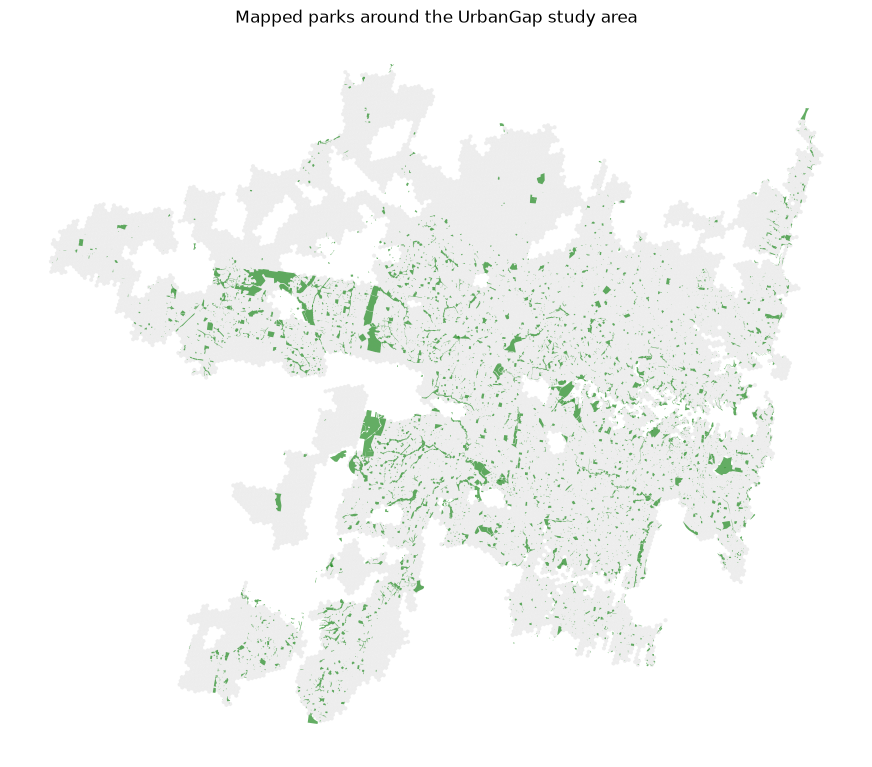

In [63]:
fig, ax = plt.subplots(figsize=(11, 11))

hex_grid.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="none",
    alpha=0.4
)

parks_nearby.plot(
    ax=ax,
    color="forestgreen",
    edgecolor="none",
    alpha=0.7
)

ax.set_title("Mapped parks around the UrbanGap study area")
ax.set_axis_off()

plt.show()

In [64]:
# Already created in Step 3
combined_parks = parks_nearby.geometry.union_all()

print("Combined park geometry type:", combined_parks.geom_type)
print("Combined park area (km²):", round(combined_parks.area / 1e6, 2))

Combined park geometry type: MultiPolygon
Combined park area (km²): 145.45


In [65]:
from shapely import intersection, area

hex_grid["park_area_inside_m2"] = area(
    intersection(
        hex_grid.geometry.array,
        combined_parks
    )
)

display(
    hex_grid["park_area_inside_m2"].describe()
)

count     16228.000000
mean       8014.407076
std       18596.198224
min           0.000000
25%           0.000000
50%           0.000000
75%        6317.657118
max      126661.033196
Name: park_area_inside_m2, dtype: float64

In [66]:
from shapely import buffer

centres = hex_grid.geometry.centroid.array

for radius in [250, 500]:

    buffers = buffer(centres, radius)

    hex_grid[f"park_area_{radius}m_m2"] = area(
        intersection(buffers, combined_parks)
    )

    print(
        f"Completed park area within {radius} m"
    )

Completed park area within 250 m
Completed park area within 500 m


In [67]:
from shapely import distance

hex_grid["distance_nearest_park_m"] = distance(
    centres,
    combined_parks
)

display(
    hex_grid["distance_nearest_park_m"].describe()
)

count    16228.000000
mean       496.634302
std        685.427032
min          0.000000
25%         96.803827
50%        222.474471
75%        536.437139
max       4600.493552
Name: distance_nearest_park_m, dtype: float64

In [68]:
park_columns = [
    "park_area_inside_m2",
    "park_area_250m_m2",
    "park_area_500m_m2",
    "distance_nearest_park_m"
]

display(
    hex_grid[park_columns].describe()
)

print("\nHexagons with park area:")
for col in park_columns[:3]:
    print(col, (hex_grid[col] > 0).sum())

print(
    "\nHexagons within 500 m of a park:",
    (hex_grid["distance_nearest_park_m"] <= 500).sum()
)

,park_area_inside_m2,park_area_250m_m2,park_area_500m_m2,distance_nearest_park_m
count,16228.000000,16228.000000,16228.000000,16228.000000
mean,8014.407076,12336.926767,48678.839454,496.634302
std,18596.198224,26505.362477,80279.547472,685.427032
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,96.803827
50%,0.000000,684.072585,19015.159771,222.474471
75%,6317.657118,11798.716410,62581.340347,536.437139
max,126661.033196,195090.322016,780361.288064,4600.493552



Hexagons with park area:
park_area_inside_m2 7624
park_area_250m_m2 8747
park_area_500m_m2 11898

Hexagons within 500 m of a park: 11903


In [69]:
print(
    "500m >= 250m:",
    (
        hex_grid["park_area_500m_m2"]
        >= hex_grid["park_area_250m_m2"] - 1e-6
    ).all()
)

print(
    "250m >= inside:",
    (
        hex_grid["park_area_250m_m2"]
        >= hex_grid["park_area_inside_m2"] - 1e-6
    ).all()
)

500m >= 250m: True
250m >= inside: True


In [70]:
hex_grid.to_file(
    "../data/processed/sydney_hex_features_v3.geojson",
    driver="GeoJSON"
)

hex_grid.drop(columns="geometry").to_csv(
    "../data/processed/sydney_hex_features_v3.csv",
    index=False
)

print("Saved", len(hex_grid), "hexagons")

Saved 16228 hexagons


In [72]:
hex_grid["hex_area_m2"] = hex_grid.geometry.area

invalid = hex_grid[
    hex_grid["park_area_inside_m2"]
    > hex_grid["hex_area_m2"] + 1e-6
]

print("Hexagons with impossible park area:", len(invalid))

display(
    hex_grid[
        ["hex_area_m2", "park_area_inside_m2"]
    ].describe()
)

Hexagons with impossible park area: 0


,hex_area_m2,park_area_inside_m2
count,16228.000000,16228.000000
mean,126627.071544,8014.407076
std,29.708853,18596.198224
min,126548.062289,0.000000
25%,126608.051292,0.000000
50%,126628.594303,0.000000
75%,126652.011267,6317.657118
max,126684.310619,126661.033196
